# Resultados del índice LLM (M3): anuncios y minutas

Todo en un lugar: la tabla de datos (que se guarda en CSV), las gráficas del índice,
la versión estandarizada, la serie trimestral, las 4 versiones, la validación contra el
peso, los episodios y la comparación de los tres métodos.

**Frecuencia.** Cada documento es un punto: un anuncio (o minuta) por decisión de política
monetaria, ≈ 8 al año. No es trimestral ni mensual. El archivo `indice_trimestral.csv` promedia
los documentos de cada trimestre (es la base de las correlaciones "suavizadas").

**Versión.** Prompt calibrado + GPT-6.1 Sol (la principal, fijada antes de ver resultados).

No llama a ningún modelo: sólo lee los resultados guardados en disco.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent / "src"))
import paths
paths.add_src_subfolders_to_path()
from sie import load_series_cached   # tipo de cambio FIX (Banxico SIE)

P = paths.PROCESSED_DIR
FIGS = paths.FIGURES_DIR   # resultados/figuras/
FIGS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.spines.top": False, "axes.spines.right": False})

PRINCIPAL = "mpu_llm_calibrated_gpt_6_1_sol"   # calibrado + Sol
VENTANA = 8                                    # promedio móvil: 8 documentos ≈ 1 año de decisiones
VENTANA_TRIM = 6                               # suavizado trimestral: 6 trimestres
z = lambda s: (s - s.mean()) / s.std()          # estandarizar: restar la media, dividir entre la desv. estándar

## 1. Los datos: un renglón por documento

In [2]:
def cargar(corpus):
    d = pd.read_parquet(P / f"banxico_{corpus}_index_llm.parquet")
    # las minutas se fechan por la decisión (se publican ~2 semanas después);
    # los anuncios salen el mismo día de la decisión
    d["fecha"] = pd.to_datetime(d["decision_date"] if "decision_date" in d else d["publication_date"]).dt.normalize()
    return d.sort_values("fecha").reset_index(drop=True)

anuncios, minutas = cargar("anuncios"), cargar("minutas")
for nombre, d in [("anuncios", anuncios), ("minutas", minutas)]:
    print(f"{nombre}: {len(d)} documentos, {d.fecha.min():%Y-%m-%d} a {d.fecha.max():%Y-%m-%d}")

anuncios: 238 documentos, 2000-01-18 a 2026-09-24
minutas: 126 documentos, 2011-01-21 a 2026-09-24


## 2. La tabla de resultados (CSV)

Por cada corpus, cuatro columnas:

| columna | qué es |
|---|---|
| `*_indice` | calificación promedio del documento (−2 a +2): los **puntos grises** de la gráfica |
| `*_promedio_movil` | promedio móvil de 8 documentos: la **línea roja** |
| `*_indice_z` | `*_indice` estandarizado: (x − media) / desv. estándar |
| `*_promedio_movil_z` | promedio móvil de `*_indice_z`: la línea de la gráfica estandarizada (la misma transformación que los puntos, así que su desv. estándar es menor que 1) |

Cada serie se estandariza con su propia muestra (anuncios 2000–2026, minutas 2011–2026).
Anuncios y minutas comparten fecha de decisión, así que van en el mismo renglón;
antes de 2011 no hay minutas (celdas vacías).

In [3]:
def columnas(d, prefijo):
    s = d.set_index("fecha")[PRINCIPAL]
    pm = s.rolling(VENTANA, min_periods=4).mean()
    return pd.DataFrame({
        f"{prefijo}_id": d.set_index("fecha").document_id,
        f"{prefijo}_indice": s,
        f"{prefijo}_promedio_movil": pm,
        f"{prefijo}_indice_z": z(s),
        f"{prefijo}_promedio_movil_z": (pm - s.mean()) / s.std(),   # = promedio móvil de indice_z
    })

por_decision = columnas(anuncios, "anuncio").join(columnas(minutas, "minuta"), how="outer")
por_decision.index.name = "fecha_decision"

# Trimestral: promedio de los documentos de cada trimestre, y su suavizado de 6 trimestres
def trimestral(d, prefijo):
    q = d.set_index("fecha")[PRINCIPAL].resample("QE").agg(["mean", "count"])
    suav = q["mean"].rolling(VENTANA_TRIM, min_periods=1).mean().where(q["count"] > 0)
    return pd.DataFrame({
        f"{prefijo}_n_docs": q["count"],
        f"{prefijo}_indice": q["mean"],
        f"{prefijo}_suavizado_6t": suav,
        f"{prefijo}_indice_z": z(q["mean"]),
        f"{prefijo}_suavizado_6t_z": (suav - q["mean"].mean()) / q["mean"].std(),   # misma transformación que indice_z
    })

trim = trimestral(anuncios, "anuncio").join(trimestral(minutas, "minuta"), how="outer")
trim.insert(0, "trimestre", trim.index.to_period("Q").astype(str))
trim.index.name = "fin_de_trimestre"
for c in ["anuncio_n_docs", "minuta_n_docs"]:
    trim[c] = trim[c].fillna(0).astype(int)

paths.RESULTS_DIR.mkdir(exist_ok=True)
por_decision.reset_index().to_csv(paths.RESULTS_DIR / "indice_por_decision.csv", index=False)
trim.reset_index().to_csv(paths.RESULTS_DIR / "indice_trimestral.csv", index=False)
print("guardado: resultados/indice_por_decision.csv y resultados/indice_trimestral.csv (las columnas se explican en el README)")
por_decision.tail(10).round(3)

guardado: resultados/indice_por_decision.csv y resultados/indice_trimestral.csv (las columnas se explican en el README)


,anuncio_id,anuncio_indice,anuncio_promedio_movil,anuncio_indice_z,anuncio_promedio_movil_z,minuta_id,minuta_indice,minuta_promedio_movil,minuta_indice_z,minuta_promedio_movil_z
fecha_decision,,,,,,,,,,
2025-08-07,banxico_apm_2025_08_07,1.000,0.688,0.683,0.184,banxico_min_2025_08_07,0.810,0.716,-0.572,-0.969
2025-09-25,banxico_apm_2025_09_25,1.000,0.812,0.683,0.384,banxico_min_2025_09_25,0.600,0.690,-1.458,-1.080
2025-11-06,banxico_apm_2025_11_06,1.000,0.979,0.683,0.650,banxico_min_2025_11_06,0.571,0.678,-1.579,-1.130
2025-12-18,banxico_apm_2025_12_18,0.667,1.021,0.150,0.717,banxico_min_2025_12_18,0.640,0.680,-1.289,-1.119
2026-02-05,banxico_apm_2026_02_05,1.000,1.021,0.683,0.717,banxico_min_2026_02_05,0.565,0.688,-1.605,-1.085
2026-03-26,banxico_apm_2026_03_26,1.000,1.021,0.683,0.717,banxico_min_2026_03_26,1.042,0.744,0.409,-0.851
2026-05-07,banxico_apm_2026_05_07,1.000,0.958,0.683,0.617,banxico_min_2026_05_07,0.750,0.729,-0.824,-0.911
2026-06-25,banxico_apm_2026_06_25,1.000,0.958,0.683,0.617,banxico_min_2026_06_25,0.304,0.660,-2.708,-1.203
2026-08-06,banxico_apm_2026_08_06,1.000,0.958,0.683,0.617,banxico_min_2026_08_06,0.435,0.613,-2.157,-1.401


In [4]:
# comprobación: indice_z tiene media 0 y desv. estándar 1; promedio_movil_z es exactamente el promedio móvil de indice_z
display(por_decision.filter(like="_indice_z").agg(["mean", "std"]).round(6))
for p in ["anuncio", "minuta"]:
    s = por_decision[f"{p}_indice_z"].dropna()
    dif = (s.rolling(VENTANA, min_periods=4).mean() - por_decision[f"{p}_promedio_movil_z"].dropna()).abs().max()
    print(f"{p}: diferencia máxima vs promedio móvil de indice_z = {dif:.1e}")

,anuncio_indice_z,minuta_indice_z
mean,-0.0,0.0
std,1.0,1.0


anuncio: diferencia máxima vs promedio móvil de indice_z = 2.2e-16
minuta: diferencia máxima vs promedio móvil de indice_z = 6.9e-16


## 3. El índice de cada corpus (estilo de la presentación)

Las franjas son episodios fijados **antes** de ver los resultados.

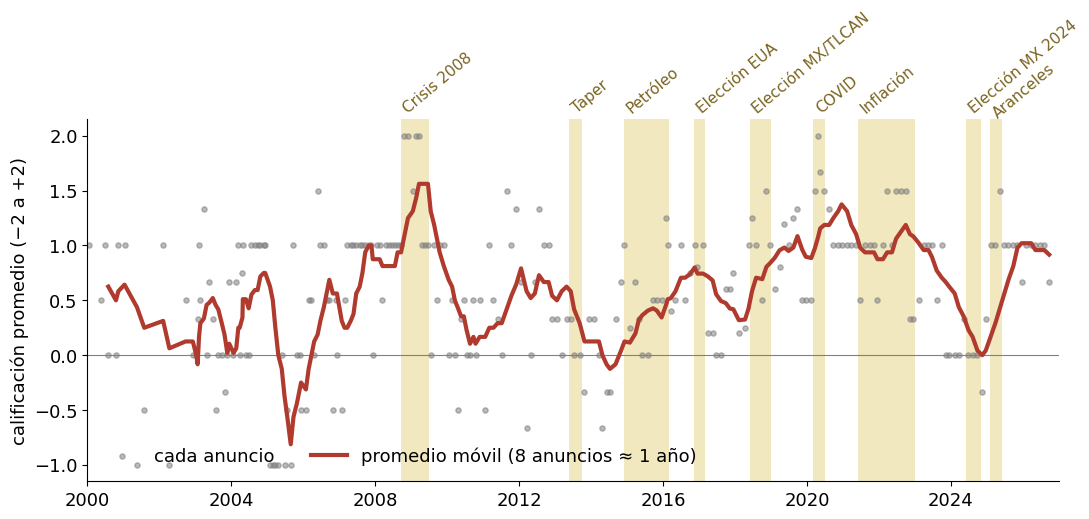

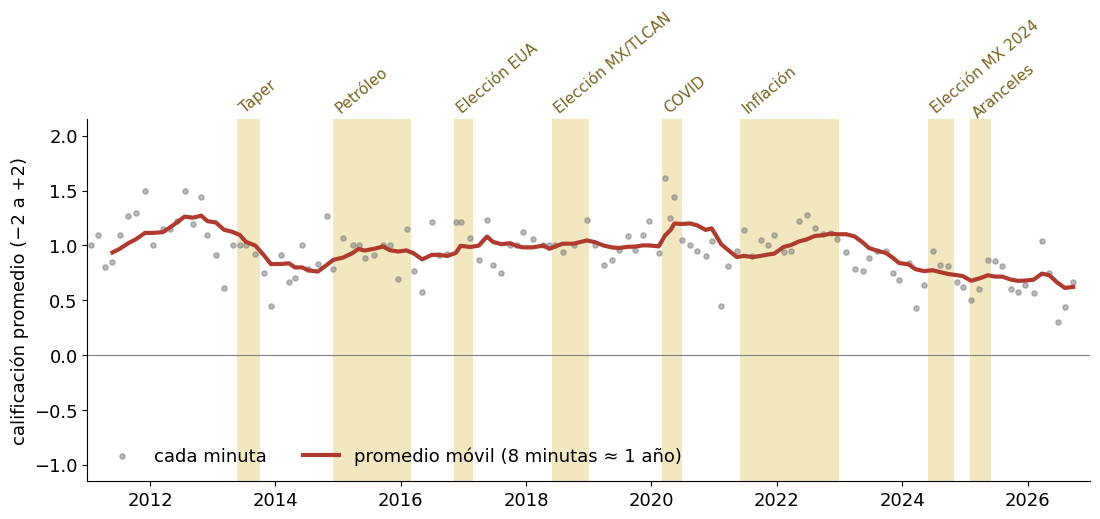

In [5]:
EPISODIOS = {   # nombre corto: (inicio, fin)
    "Crisis 2008":       ("2008-09-15", "2009-06-30"),
    "Taper":             ("2013-05-22", "2013-09-30"),
    "Petróleo":          ("2014-12-01", "2016-02-29"),
    "Elección EUA":      ("2016-11-08", "2017-02-28"),
    "Elección MX/TLCAN": ("2018-06-01", "2018-12-31"),
    "COVID":             ("2020-03-01", "2020-06-30"),
    "Inflación":         ("2021-06-01", "2022-12-31"),
    "Elección MX 2024":  ("2024-06-01", "2024-10-31"),
    "Aranceles":         ("2025-02-01", "2025-05-31"),
}
ROJO, BEIGE, OLIVO = "#B03A2E", "#F2E8C0", "#7A6420"

def sombrear(ax, desde=None, etiquetas=True):
    for i, (nombre, (a, b)) in enumerate(EPISODIOS.items()):
        a, b = pd.Timestamp(a), pd.Timestamp(b)
        if desde is not None and b < desde:
            continue
        ax.axvspan(a, b, color=BEIGE, zorder=0, lw=0)
        if etiquetas:
            # "Aranceles" va un poco más abajo para no encimarse con "Elección MX 2024"
            ax.text(a, 1.01 if nombre != "Aranceles" else 0.995, nombre, transform=ax.get_xaxis_transform(),
                    rotation=40, ha="left", va="bottom", fontsize=11, color=OLIVO)

def grafica_indice(d, documento, estandarizar=False, archivo=None):
    # estandarizar=True: misma gráfica en desviaciones estándar. Los puntos son z(índice) y la línea es
    # el promedio móvil de esos puntos (la misma forma, sólo cambia la escala del eje).
    x = z(d[PRINCIPAL]) if estandarizar else d[PRINCIPAL]
    fig, ax = plt.subplots(figsize=(11.1, 5.3))
    ax.scatter(d.fecha, x, s=14, color="gray", alpha=0.55, label=f"cada {documento}", zorder=2)
    ax.plot(d.fecha, x.rolling(VENTANA, min_periods=4).mean(), color=ROJO, lw=3,
            label=f"promedio móvil ({VENTANA} {documento}s ≈ 1 año)", zorder=3)
    ax.axhline(0, color="gray", lw=0.8)
    if estandarizar:
        ax.set_ylabel(f"desv. estándar (0 = promedio {d.fecha.min():%Y}–{d.fecha.max():%Y})", fontsize=13)
        ax.set_ylim(-3.6, 3.2)
    else:
        ax.set_ylabel("calificación promedio (−2 a +2)", fontsize=13)
        ax.set_ylim(-1.15, 2.15)
    ax.tick_params(labelsize=13)
    ax.set_xlim(pd.Timestamp(f"{d.fecha.min().year}-01-01"), pd.Timestamp("2026-12-31"))
    sombrear(ax, desde=d.fecha.min())
    ax.legend(loc="lower left", ncol=2, frameon=False, fontsize=13)
    fig.tight_layout()
    if archivo:
        fig.savefig(archivo, dpi=200, bbox_inches="tight")
    plt.show()

# (las versiones que van a la presentación se guardan en la sección 11)
grafica_indice(anuncios, "anuncio")
grafica_indice(minutas, "minuta")

## 4. Estandarizado: anuncios y minutas en la misma escala

0 = nivel típico de ese corpus; las unidades son desviaciones estándar.

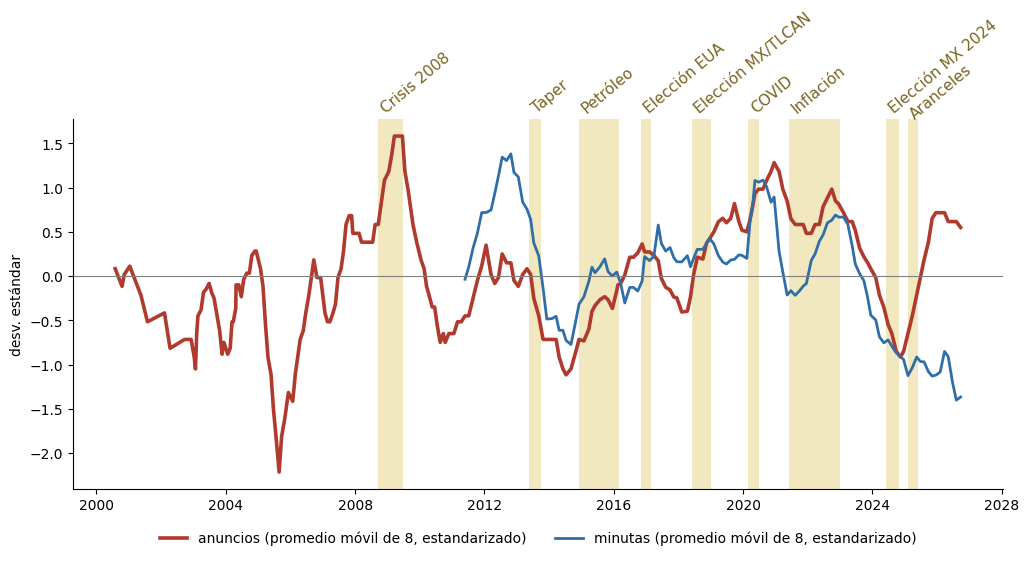

correlación anuncios vs minutas (mismas decisiones, 126): por documento 0.30, promedio móvil 0.35


In [6]:
fig, ax = plt.subplots(figsize=(12, 4.8))
for d, nombre, color, lw in [(anuncios, "anuncios", ROJO, 2.6), (minutas, "minutas", "#2F6EA8", 2)]:
    pm = d.set_index("fecha")[PRINCIPAL].rolling(VENTANA, min_periods=4).mean()
    s = d.set_index("fecha")[PRINCIPAL]
    ax.plot(pm.index, (pm - s.mean()) / s.std(), color=color, lw=lw, label=f"{nombre} (promedio móvil de 8, estandarizado)")
ax.axhline(0, color="gray", lw=0.8); ax.set_ylabel("desv. estándar")
sombrear(ax)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)
plt.show()

comun = por_decision.dropna(subset=["anuncio_indice", "minuta_indice"])
print(f"correlación anuncios vs minutas (mismas decisiones, {len(comun)}): "
      f"por documento {comun.anuncio_indice.corr(comun.minuta_indice):.2f}, "
      f"promedio móvil {comun.anuncio_promedio_movil.corr(comun.minuta_promedio_movil):.2f}")

## 5. Frecuencia: por qué un punto por decisión, y la versión trimestral

**La frecuencia la pone Banxico, no nosotros.** El documento es la unidad de observación:
hay un anuncio (y una minuta) por decisión de política monetaria. Desde 2011 son 8 decisiones
programadas al año; entre 2003 y 2010, 11–14 (casi mensual); en 2000–2002, de 3 a 6.
No hay información entre una reunión y otra: el banco no escribe nada.

**Por qué no interpolar a 12 por año:** inventaría observaciones que no existen. Los meses
interpolados usarían la reunión *siguiente* (información del futuro) y harían parecer que
tenemos más datos de los que hay. Si se necesita una serie mensual para cruzarla con datos
mensuales, lo correcto es **repetir la última lectura** hasta la siguiente decisión (como se
hace con la tasa de política), sabiendo que no agrega información.

**Trimestral** es la agregación natural: promedio de los documentos de cada trimestre
(casi siempre 2; sólo 2001T4 no tiene ningún anuncio). Es la misma base de las correlaciones
"suavizadas" con el peso.

**Rezago del promedio móvil.** Todos los promedios móviles de este notebook miran hacia atrás
(el documento actual y los anteriores). Los picos aparecen unos meses tarde: con 8 documentos,
~½ año; con 6 trimestres, ~2½ trimestres. Por eso conviene mostrar también los puntos sin suavizar.

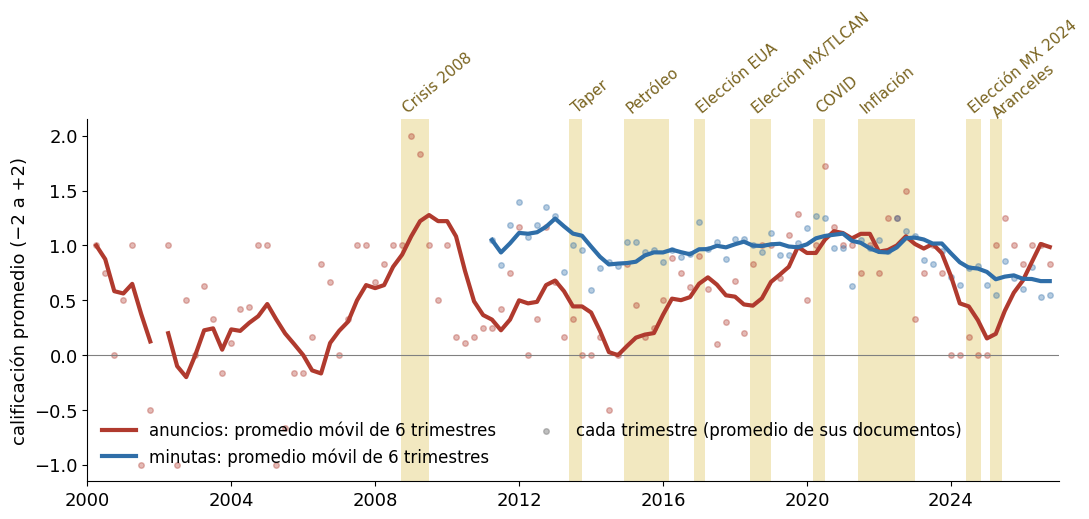

In [7]:
# Índice trimestral, anuncios y minutas
AZUL = "#2F6EA8"

def grafica_trimestral(estandarizar=False, archivo=None):
    # estandarizar=True: cada corpus con su propia media y desv. estándar trimestral.
    # La línea se transforma igual que los puntos, así que sigue siendo su promedio móvil.
    fig, ax = plt.subplots(figsize=(11.1, 5.3))
    for prefijo, nombre, color in [("anuncio", "anuncios", ROJO), ("minuta", "minutas", AZUL)]:
        q, suav = trim[f"{prefijo}_indice"], trim[f"{prefijo}_suavizado_6t"]
        if estandarizar:
            q, suav = (q - q.mean()) / q.std(), (suav - q.mean()) / q.std()
        ax.scatter(trim.index, q, s=16, color=color, alpha=0.35, zorder=2)
        ax.plot(trim.index, suav, color=color, lw=3, zorder=3, label=f"{nombre}: promedio móvil de 6 trimestres")
    ax.scatter([], [], s=16, color="gray", alpha=0.5, label="cada trimestre (promedio de sus documentos)")
    ax.axhline(0, color="gray", lw=0.8)
    if estandarizar:
        ax.set_ylabel("desv. estándar (0 = promedio de cada serie)", fontsize=13)
        ax.set_ylim(-3.6, 3.2)
    else:
        ax.set_ylabel("calificación promedio (−2 a +2)", fontsize=13)
        ax.set_ylim(-1.15, 2.15)
    ax.tick_params(labelsize=13)
    ax.set_xlim(pd.Timestamp("2000-01-01"), pd.Timestamp("2026-12-31"))
    sombrear(ax)
    ax.legend(loc="lower left", ncol=2, frameon=False, fontsize=12)
    fig.tight_layout()
    if archivo:
        fig.savefig(archivo, dpi=200, bbox_inches="tight")
    plt.show()

grafica_trimestral()

### Trimestral, crudo vs estandarizado

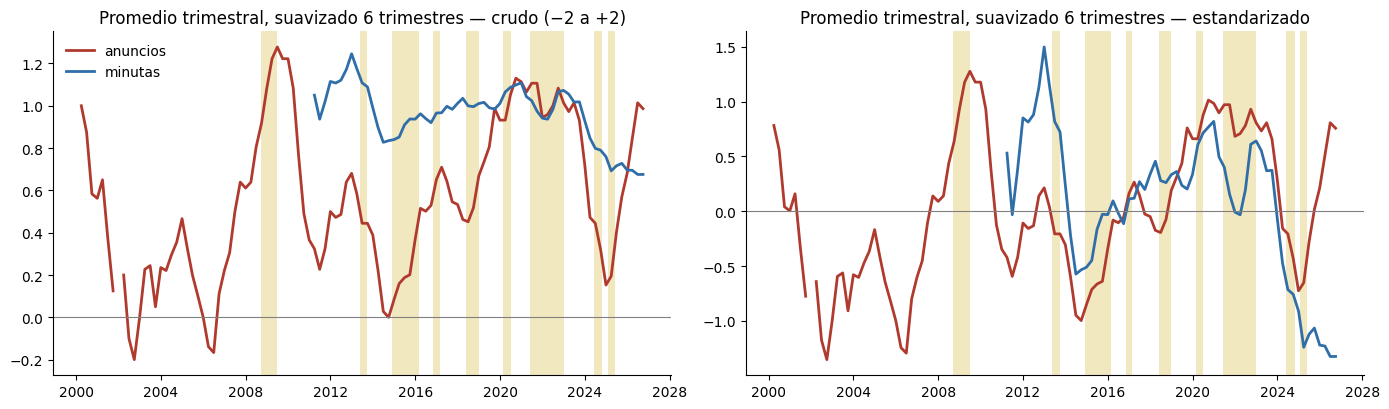

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, cols, titulo in [(axes[0], ["anuncio_suavizado_6t", "minuta_suavizado_6t"], "crudo (−2 a +2)"),
                         (axes[1], ["anuncio_suavizado_6t_z", "minuta_suavizado_6t_z"], "estandarizado")]:
    for c, color in zip(cols, [ROJO, "#2F6EA8"]):
        ax.plot(trim.index, trim[c], color=color, lw=2, label=c.split("_")[0] + "s")
    ax.set_title(f"Promedio trimestral, suavizado 6 trimestres — {titulo}")
    ax.axhline(0, color="gray", lw=0.8); sombrear(ax, etiquetas=False)
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

## 6. Las 4 versiones (2 prompts × 2 modelos), estandarizadas

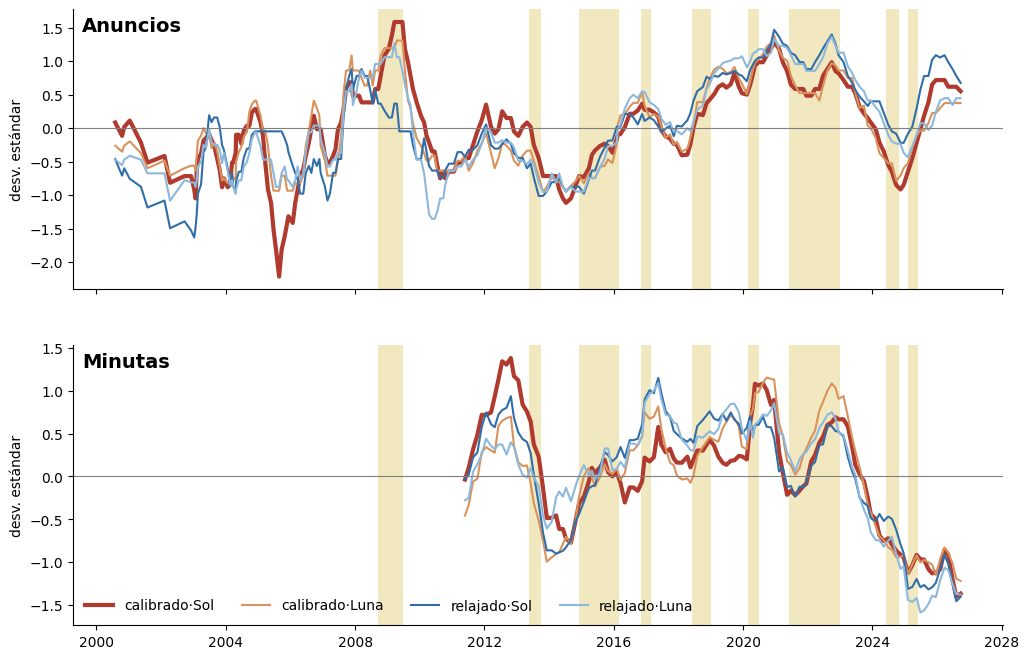


anuncios: correlación entre versiones (promedio móvil de 8)


,calibrado·Sol,calibrado·Luna,relajado·Sol,relajado·Luna
calibrado·Sol,1.00,0.91,0.70,0.85
calibrado·Luna,0.91,1.00,0.79,0.93
relajado·Sol,0.70,0.79,1.00,0.87
relajado·Luna,0.85,0.93,0.87,1.00



minutas: correlación entre versiones (promedio móvil de 8)


,calibrado·Sol,calibrado·Luna,relajado·Sol,relajado·Luna
calibrado·Sol,1.00,0.87,0.87,0.81
calibrado·Luna,0.87,1.00,0.90,0.91
relajado·Sol,0.87,0.90,1.00,0.93
relajado·Luna,0.81,0.91,0.93,1.00


In [9]:
VERSIONES = {"mpu_llm_calibrated_gpt_6_1_sol": ("calibrado·Sol", ROJO, 3),
             "mpu_llm_calibrated_gpt_6_luna": ("calibrado·Luna", "#D9925B", 1.5),
             "mpu_llm_lax_gpt_6_1_sol": ("relajado·Sol", "#2F6EA8", 1.5),
             "mpu_llm_lax_gpt_6_luna": ("relajado·Luna", "#8DB8DD", 1.5)}

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for ax, d, nombre in [(axes[0], anuncios, "Anuncios"), (axes[1], minutas, "Minutas")]:
    for col, (etq, color, lw) in VERSIONES.items():
        ax.plot(d.fecha, z(d[col]).rolling(VENTANA, min_periods=4).mean(), color=color, lw=lw, label=etq)
    ax.axhline(0, color="gray", lw=0.8); ax.set_ylabel("desv. estándar")
    ax.text(0.01, 0.92, nombre, transform=ax.transAxes, fontsize=14, fontweight="bold")
    sombrear(ax, etiquetas=False)
axes[1].legend(loc="lower left", ncol=4, frameon=False)
plt.show()

etiquetas = {c: v[0] for c, v in VERSIONES.items()}
for nombre, d in [("anuncios", anuncios), ("minutas", minutas)]:
    print(f"\n{nombre}: correlación entre versiones (promedio móvil de 8)")
    display(d[list(VERSIONES)].rolling(VENTANA, min_periods=VENTANA).mean().corr()
            .rename(index=etiquetas, columns=etiquetas).round(2))

## 7. Validación: volatilidad del peso

Por documento: volatilidad del FIX en los 30 días antes de la decisión.
Trimestral: volatilidad de los rendimientos diarios de cada trimestre; las dos series suavizadas 6 trimestres.

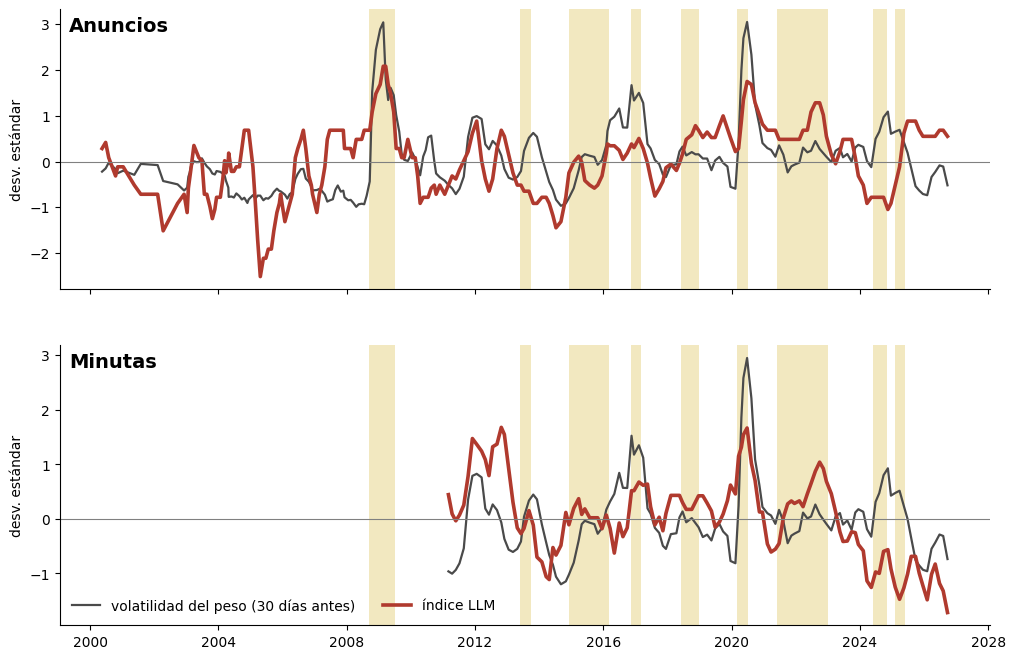

In [10]:
fix = load_series_cached("exchange_rate", P).set_index("date")["value"].sort_index()
rend = np.log(fix).diff().dropna()

def volatilidad_antes(fecha, dias=30):
    r = rend[(rend.index > fecha - pd.Timedelta(days=dias)) & (rend.index <= fecha)]
    return r.std() * np.sqrt(252) * 100 if len(r) >= 10 else np.nan

for d in (anuncios, minutas):
    d["vol_peso"] = d.fecha.apply(volatilidad_antes)

vol_trim = rend.resample("QE").std() * np.sqrt(252) * 100

def corr_suavizada(d, col):
    q = d.set_index("fecha")[col].resample("QE").mean()
    s = pd.concat([q.rolling(VENTANA_TRIM, min_periods=1).mean().rename("x"),
                   vol_trim.rolling(VENTANA_TRIM, min_periods=1).mean().rename("vol")], axis=1, join="inner")
    return s.loc[q.dropna().index.intersection(s.index)].dropna().corr().iloc[0, 1]

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for ax, d, nombre in [(axes[0], anuncios, "Anuncios"), (axes[1], minutas, "Minutas")]:
    ax.plot(d.fecha, z(d.vol_peso).rolling(4, min_periods=2).mean(), color="#4A4A4A", lw=1.6,
            label="volatilidad del peso (30 días antes)")
    ax.plot(d.fecha, z(d[PRINCIPAL]).rolling(4, min_periods=2).mean(), color=ROJO, lw=2.6, label="índice LLM")
    ax.axhline(0, color="gray", lw=0.8); ax.set_ylabel("desv. estándar")
    ax.text(0.01, 0.92, nombre, transform=ax.transAxes, fontsize=14, fontweight="bold")
    sombrear(ax, etiquetas=False)
axes[1].legend(loc="lower left", ncol=2, frameon=False)
plt.show()

## 8. Los tres métodos contra el peso

In [11]:
METODOS = {"unc_rate_policy": "M1 diccionario", "mpu_embed": "M2 embeddings", PRINCIPAL: "M3 LLM"}
tabla, tres = {}, {}
for corpus, d in [("anuncios", anuncios), ("minutas", minutas)]:
    m1 = pd.read_parquet(P / f"banxico_{corpus}_index_exact_matching.parquet")[["document_id", "unc_rate_policy"]]
    m2 = pd.read_parquet(P / f"banxico_{corpus}_index_embeddings.parquet")[["document_id", "mpu_embed"]]
    t = d.merge(m1, on="document_id").merge(m2, on="document_id")
    tres[corpus] = t
    for col, nombre in METODOS.items():
        tabla[(nombre, corpus, "por doc")] = t[col].corr(t.vol_peso)
        tabla[(nombre, corpus, "suavizado")] = corr_suavizada(t, col)

pd.Series(tabla).unstack([1, 2]).round(2)

anuncios           minutas          
                por doc suavizado por doc suavizado
M1 diccionario     0.11      0.36    0.04     -0.10
M2 embeddings      0.33      0.53    0.35      0.30
M3 LLM             0.37      0.57    0.37      0.26

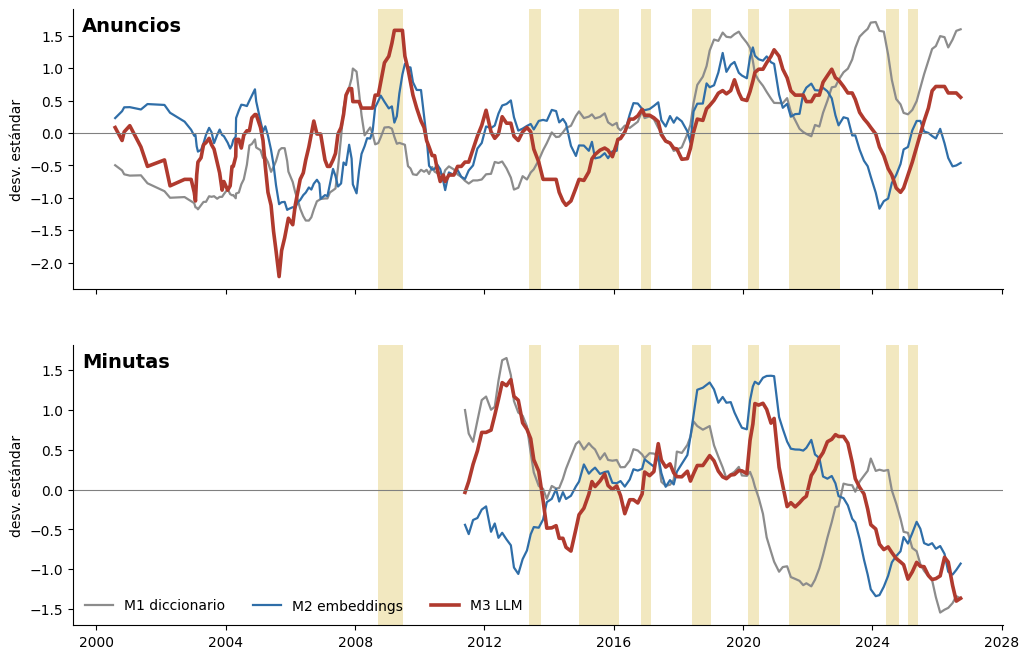

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for ax, (corpus, t) in zip(axes, tres.items()):
    for (col, nombre), color in zip(METODOS.items(), ["#8C8C8C", "#2F6EA8", ROJO]):
        ax.plot(t.fecha, z(t[col]).rolling(VENTANA, min_periods=4).mean(), color=color,
                lw=2.6 if col == PRINCIPAL else 1.6, label=nombre)
    ax.axhline(0, color="gray", lw=0.8); ax.set_ylabel("desv. estándar")
    ax.text(0.01, 0.92, corpus.capitalize(), transform=ax.transAxes, fontsize=14, fontweight="bold")
    sombrear(ax, etiquetas=False)
axes[1].legend(loc="lower left", ncol=3, frameon=False)
plt.show()

## 9. Episodio por episodio

Percentil promedio de los documentos dentro de cada episodio (50 = típico, 100 = el más alto).

In [13]:
filas = []
for nombre, (a, b) in EPISODIOS.items():
    fila = {"episodio": nombre}
    for corpus, d in [("anuncios", anuncios), ("minutas", minutas)]:
        pct = d[[PRINCIPAL, "vol_peso"]].rank(pct=True) * 100
        m = d.fecha.between(a, b)
        fila[(corpus, "n")] = int(m.sum())
        fila[(corpus, "índice LLM")] = pct.loc[m, PRINCIPAL].mean().round() if m.any() else np.nan
        fila[(corpus, "vol. peso")] = pct.loc[m, "vol_peso"].mean().round() if m.any() else np.nan
    filas.append(fila)
episodios = pd.DataFrame(filas).set_index("episodio")
episodios.columns = pd.MultiIndex.from_tuples(episodios.columns)
episodios

anuncios                      minutas                     
                         n índice LLM vol. peso       n índice LLM vol. peso
episodio                                                                    
Crisis 2008              9       87.0      92.0       0        NaN       NaN
Taper                    3       24.0      82.0       3       54.0      75.0
Petróleo                11       47.0      67.0      10       51.0      54.0
Elección EUA             3       67.0      85.0       3       83.0      79.0
Elección MX/TLCAN        5       75.0      68.0       4       64.0      53.0
COVID                    4       97.0      97.0       4       90.0      96.0
Inflación               13       69.0      62.0      13       71.0      52.0
Elección MX 2024         3       19.0      88.0       3       35.0      83.0
Aranceles                3       80.0      74.0       3       16.0      67.0

## 10. ¿Cómo usa la escala cada prompt? (calibrado vs relajado, Sol)

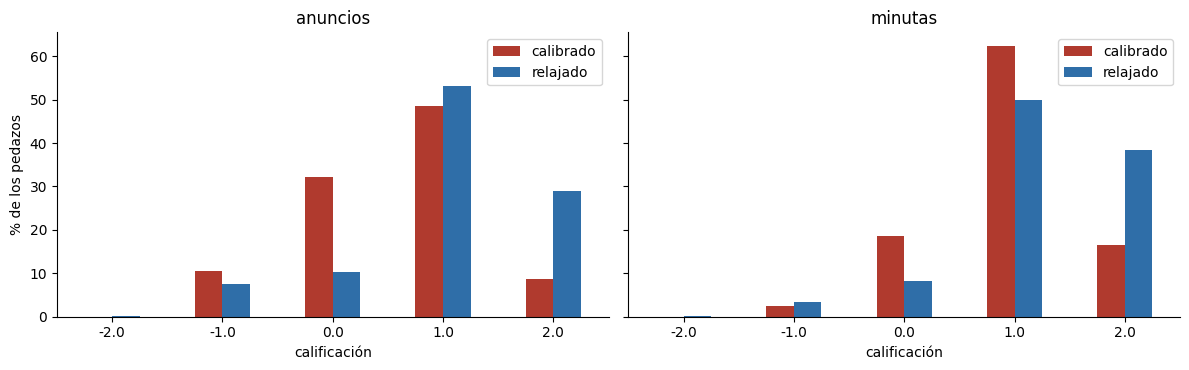

anuncios            minutas         
                  calibrado relajado calibrado relajado
uncertainty_score                                      
-2.0                    0.0      0.0       0.0      0.0
-1.0                   11.0      7.0       2.0      3.0
 0.0                   32.0     10.0      19.0      8.0
 1.0                   49.0     53.0      62.0     50.0
 2.0                    9.0     29.0      16.0     38.0

In [14]:
S = P / "llm_scores"
dist = {}
for corpus in ["anuncios", "minutas"]:
    for prompt, etq in [("calibrated", "calibrado"), ("lax", "relajado")]:
        s = pd.read_parquet(S / f"banxico_{corpus}__{prompt}__openai_gpt-6.1-sol.parquet").uncertainty_score
        dist[(corpus, etq)] = s.value_counts(normalize=True) * 100
dist = pd.DataFrame(dist).sort_index().fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, corpus in zip(axes, ["anuncios", "minutas"]):
    dist[corpus].plot.bar(ax=ax, rot=0, color=[ROJO, "#2F6EA8"])
    ax.set_title(corpus); ax.set_xlabel("calificación"); ax.set_ylabel("% de los pedazos")
plt.tight_layout(); plt.show()
dist.round(0)

## 11. Las figuras de la presentación (`presentacion/pres_text_analysis_sin_notas.pptx`)

Cada gráfica de la presentación sale de una celda de esta sección, que la guarda en
`resultados/figuras/`. Las diapositivas 4 y 5 (clasificación FOMC y EPU) son
imágenes de la literatura, no resultados nuestros.

| diapositiva | archivo |
|---|---|
| Metodología: importancia del prompt | `04_calibrado_vs_relajado.png` |
| Resultados: índice de anuncios | `01_indice_anuncios.png` |
| … estandarizado | `09_indice_anuncios_z.png` |
| Resultados: índice de minutas | `07_indice_minutas.png` |
| … estandarizado | `10_indice_minutas_z.png` |
| Resultados: índice trimestral | `08_indice_trimestral.png` |
| … estandarizado | `11_indice_trimestral_z.png` |
| Cuatro diseños que cuentan lo mismo | `03_cuatro_versiones.png` |
| Validación externa: índice vs. volatilidad del peso | `02_indice_vs_peso.png` |
| Los tres métodos vs volatilidad del peso | `06_correlaciones.png` |
| 3 metodologías | `05_tres_metodos.png` |

Si cambias una figura aquí, vuelve a insertar el PNG en la diapositiva: la presentación
guarda su propia copia de la imagen.

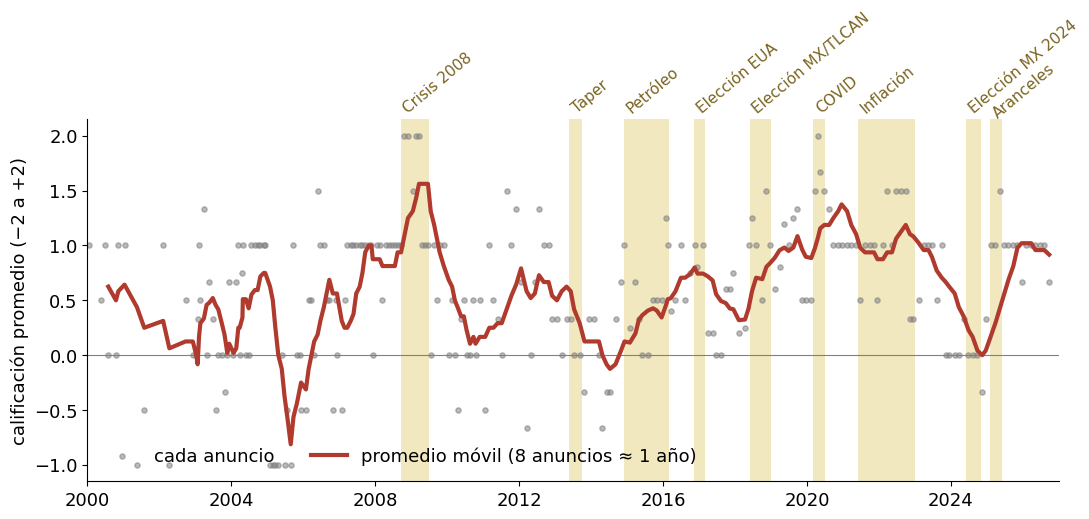

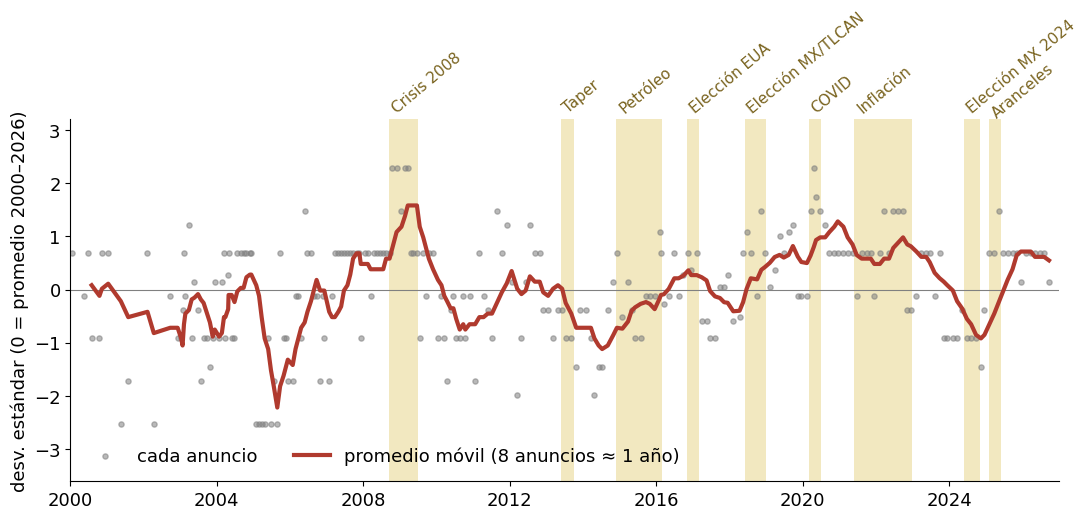

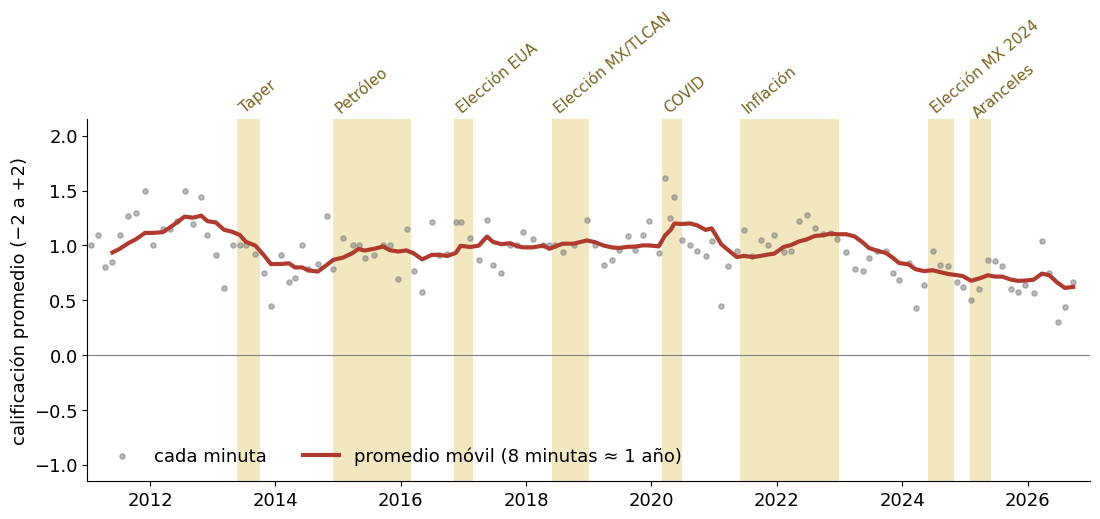

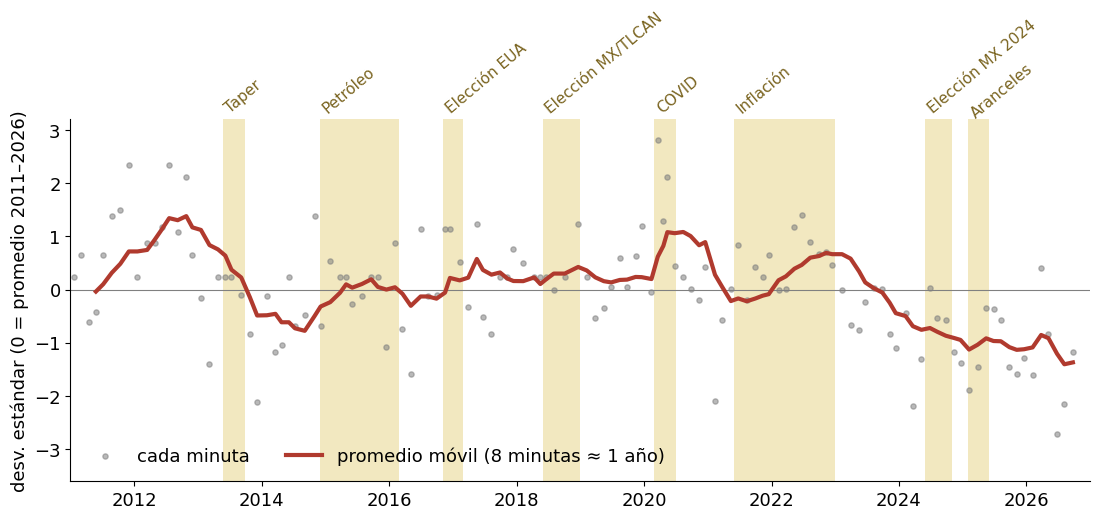

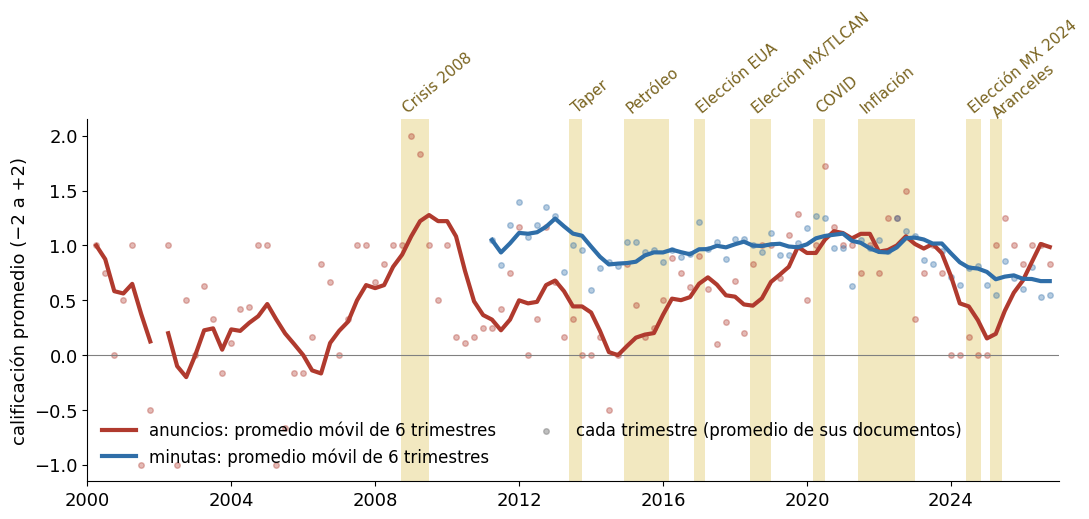

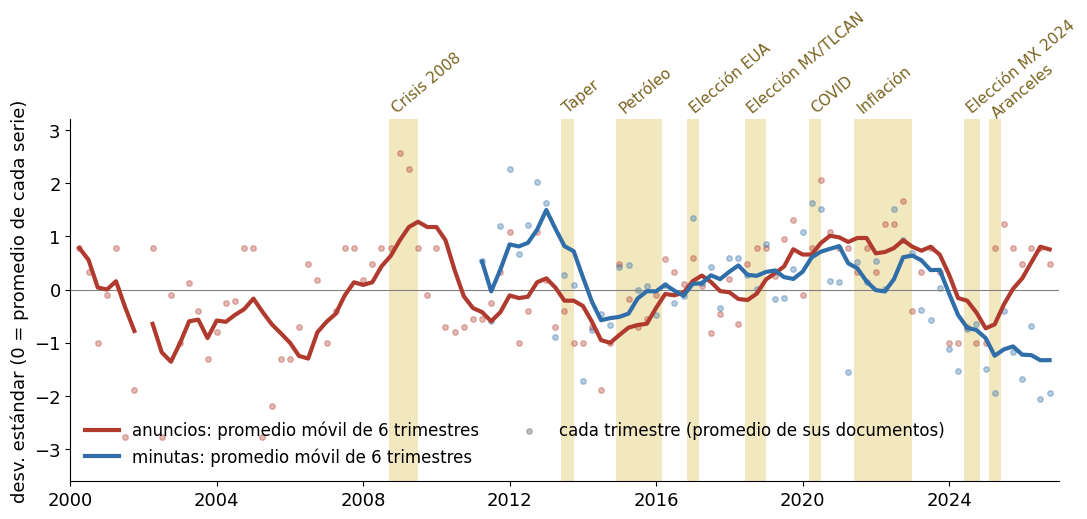

anuncios: media 0.57, desv. estándar 0.63 (un punto en la escala −2…+2 = 1.6 desv. estándar)
minutas: media 0.94, desv. estándar 0.24 (un punto en la escala −2…+2 = 4.2 desv. estándar)


In [15]:
# Índices por documento (crudo y estandarizado) y trimestral (crudo y estandarizado)
grafica_indice(anuncios, "anuncio", archivo=FIGS / "01_indice_anuncios.png")
grafica_indice(anuncios, "anuncio", estandarizar=True, archivo=FIGS / "09_indice_anuncios_z.png")
grafica_indice(minutas, "minuta", archivo=FIGS / "07_indice_minutas.png")
grafica_indice(minutas, "minuta", estandarizar=True, archivo=FIGS / "10_indice_minutas_z.png")
grafica_trimestral(archivo=FIGS / "08_indice_trimestral.png")
grafica_trimestral(estandarizar=True, archivo=FIGS / "11_indice_trimestral_z.png")

for nombre, d in [("anuncios", anuncios), ("minutas", minutas)]:
    print(f"{nombre}: media {d[PRINCIPAL].mean():.2f}, desv. estándar {d[PRINCIPAL].std():.2f} "
          f"(un punto en la escala −2…+2 = {1 / d[PRINCIPAL].std():.1f} desv. estándar)")

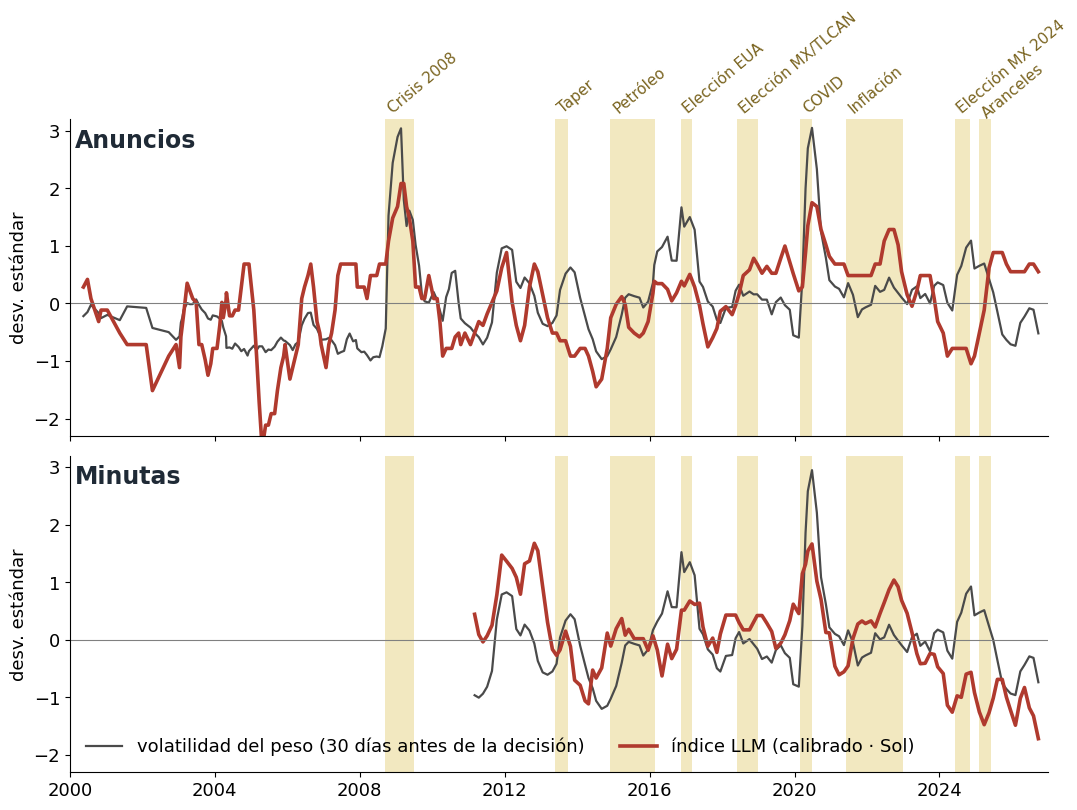

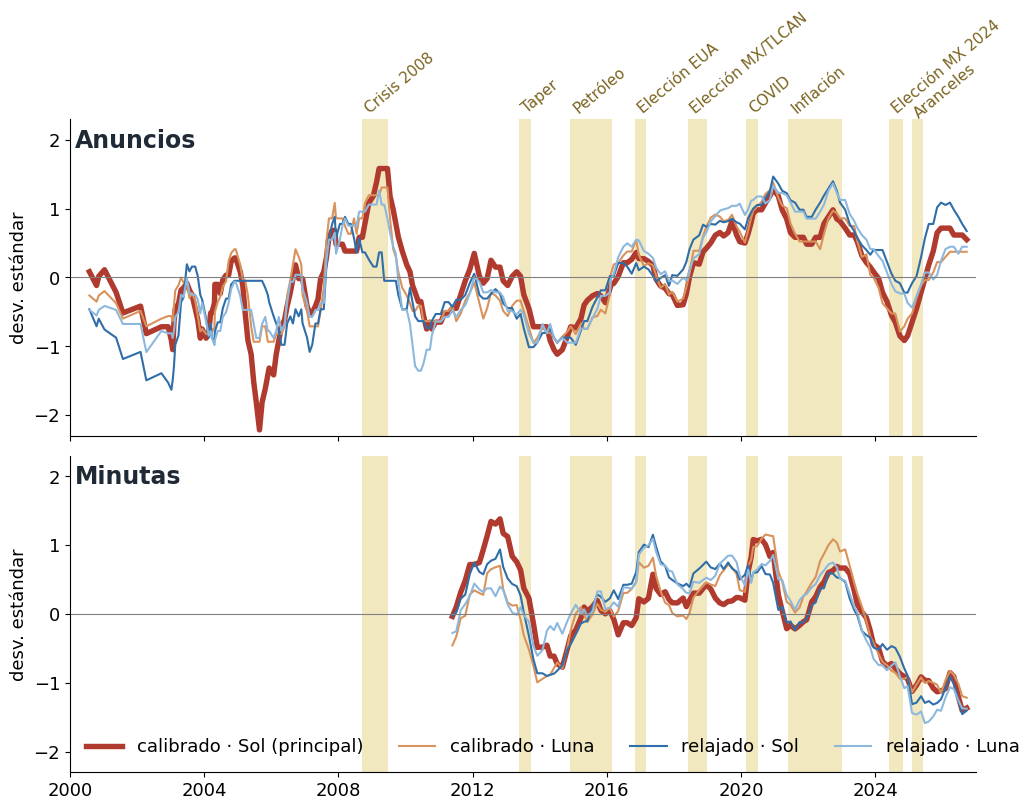

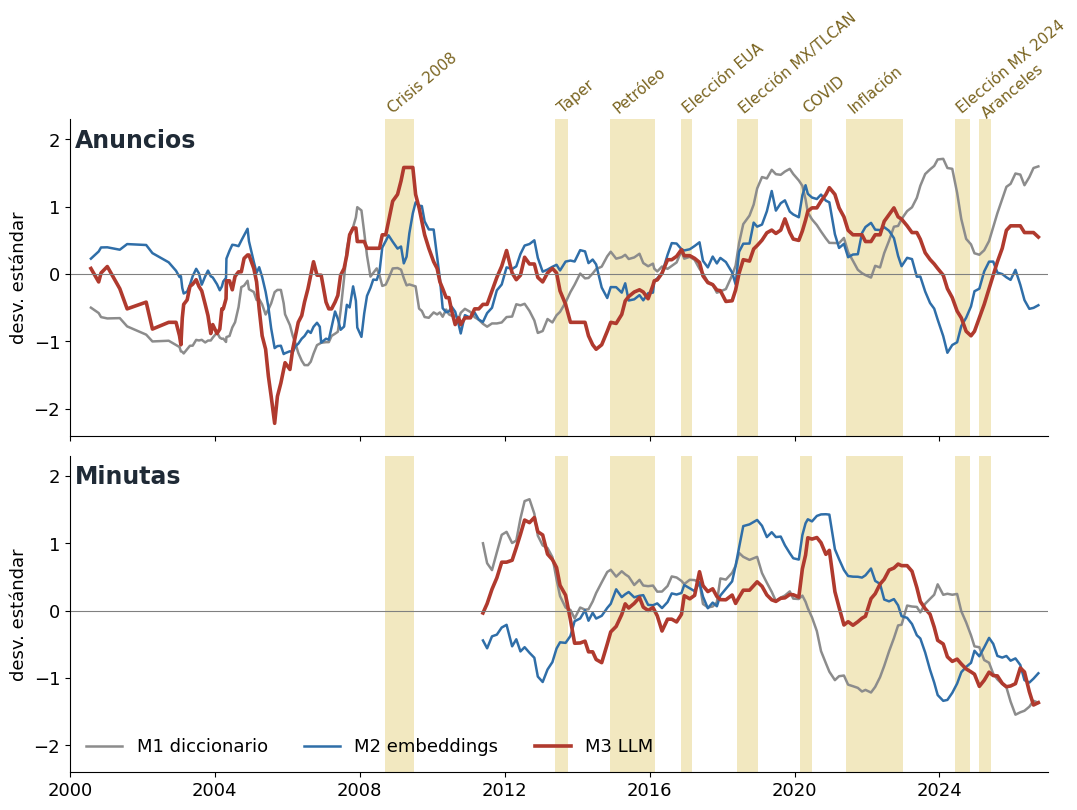

In [16]:
# Paneles: anuncios arriba, minutas abajo (estilo común de las figuras 02, 03 y 05)
TINTA = "#1F2A36"

def dos_paneles(dibujar, ylim, archivo, ncol_leyenda):
    fig, axes = plt.subplots(2, 1, figsize=(11, 8.2), sharex=True)
    for ax, d, nombre in [(axes[0], anuncios, "Anuncios"), (axes[1], minutas, "Minutas")]:
        dibujar(ax, d)
        ax.axhline(0, color="gray", lw=0.8)
        ax.set_ylabel("desv. estándar", fontsize=13); ax.set_ylim(*ylim); ax.tick_params(labelsize=13)
        ax.text(0.005, 0.97, nombre, transform=ax.transAxes, fontsize=17, fontweight="bold", color=TINTA, va="top")
        sombrear(ax, etiquetas=(ax is axes[0]))
    axes[1].set_xlim(pd.Timestamp("2000-01-01"), pd.Timestamp("2026-12-31"))
    axes[1].legend(loc="lower left", ncol=ncol_leyenda, frameon=False, fontsize=13)
    fig.tight_layout()
    fig.savefig(archivo, dpi=200, bbox_inches="tight")
    plt.show()

# 02 — índice vs volatilidad del peso (estandarizados, promedio móvil de 4 documentos)
def peso(ax, d):
    ax.plot(d.fecha, z(d.vol_peso).rolling(4, min_periods=2).mean(), color="#4A4A4A", lw=1.6,
            label="volatilidad del peso (30 días antes de la decisión)")
    ax.plot(d.fecha, z(d[PRINCIPAL]).rolling(4, min_periods=2).mean(), color=ROJO, lw=2.6,
            label="índice LLM (calibrado · Sol)")
dos_paneles(peso, (-2.3, 3.2), FIGS / "02_indice_vs_peso.png", 2)

# 03 — las cuatro versiones (estandarizadas, promedio móvil de 8 documentos)
def versiones(ax, d):
    for col, (etq, color, lw) in VERSIONES.items():
        etq = etq.replace("·", " · ") + (" (principal)" if col == PRINCIPAL else "")
        ax.plot(d.fecha, z(d[col]).rolling(VENTANA, min_periods=4).mean(), color=color,
                lw=lw * 1.3 if col == PRINCIPAL else lw, label=etq)
dos_paneles(versiones, (-2.3, 2.3), FIGS / "03_cuatro_versiones.png", 4)

# 05 — los tres métodos (estandarizados, promedio móvil de 8 documentos)
def metodos(ax, d):
    t = tres["anuncios" if d is anuncios else "minutas"]
    for (col, nombre), color in zip(METODOS.items(), ["#8C8C8C", AZUL, ROJO]):
        ax.plot(t.fecha, z(t[col]).rolling(VENTANA, min_periods=4).mean(), color=color,
                lw=2.6 if col == PRINCIPAL else 1.8, label=nombre)
dos_paneles(metodos, (-2.4, 2.3), FIGS / "05_tres_metodos.png", 3)

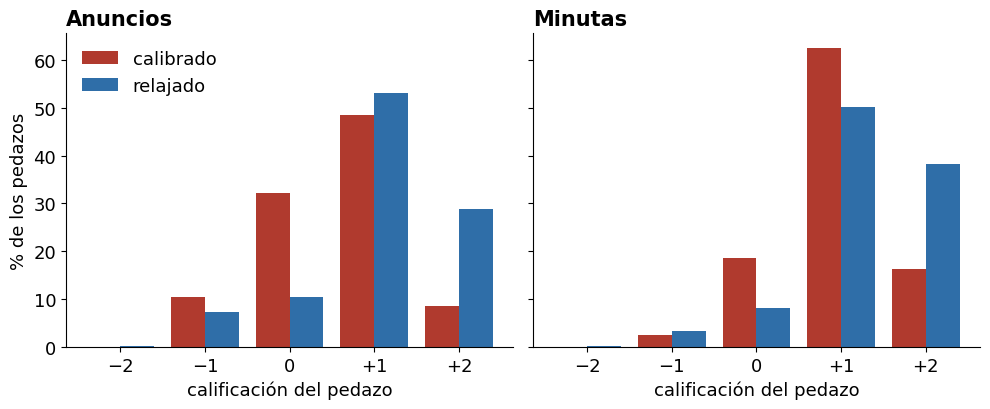

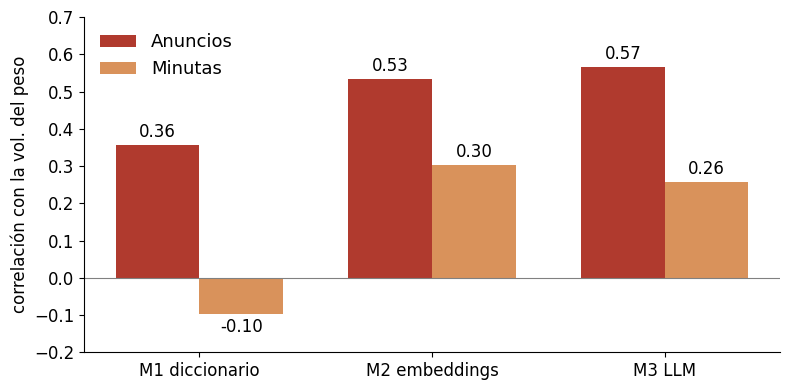

In [17]:
# 04 — cómo usa la escala cada prompt (calibrado vs relajado, GPT-6.1 Sol)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for ax, corpus in zip(axes, ["anuncios", "minutas"]):
    x = np.arange(5)
    for k, (etq, color) in enumerate([("calibrado", ROJO), ("relajado", AZUL)]):
        ax.bar(x + (k - 0.5) * 0.4, dist[(corpus, etq)].reindex([-2.0, -1.0, 0.0, 1.0, 2.0]).fillna(0),
               width=0.4, color=color, label=etq)
    ax.set_xticks(x, ["−2", "−1", "0", "+1", "+2"])
    ax.set_xlabel("calificación del pedazo", fontsize=13); ax.tick_params(labelsize=13)
    ax.set_title(corpus.capitalize(), loc="left", fontsize=15, fontweight="bold")
axes[0].set_ylabel("% de los pedazos", fontsize=13)
axes[0].legend(frameon=False, fontsize=13)
fig.tight_layout()
fig.savefig(FIGS / "04_calibrado_vs_relajado.png", dpi=200, bbox_inches="tight")
plt.show()

# 06 — correlación con la volatilidad del peso, trimestral suavizada (tabla de la sección 8)
suav = pd.Series(tabla).unstack([1, 2]).xs("suavizado", axis=1, level=1).loc[list(METODOS.values())]
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(suav))
for k, (corpus, color) in enumerate([("anuncios", ROJO), ("minutas", "#D9925B")]):
    barras = ax.bar(x + (k - 0.5) * 0.36, suav[corpus], width=0.36, color=color, label=corpus.capitalize())
    ax.bar_label(barras, fmt="%.2f", padding=3, fontsize=12)
ax.axhline(0, color="gray", lw=0.8)
ax.set_xticks(x, suav.index); ax.tick_params(labelsize=12)
ax.set_ylabel("correlación con la vol. del peso", fontsize=12); ax.set_ylim(-0.2, 0.7)
ax.legend(frameon=False, fontsize=13, loc="upper left")
fig.tight_layout()
fig.savefig(FIGS / "06_correlaciones.png", dpi=200, bbox_inches="tight")
plt.show()